In [6]:
   %pip install shap xgboost statsmodels

Defaulting to user installation because normal site-packages is not writeableNote: you may need to restart the kernel to use updated packages.



In [7]:
%pip install "numpy<2"

Defaulting to user installation because normal site-packages is not writeable
  Using cached numpy-1.26.4-cp312-cp312-win_amd64.whl.metadata (61 kB)
Using cached numpy-1.26.4-cp312-cp312-win_amd64.whl (15.5 MB)
  Attempting uninstall: numpy
    Found existing installation: numpy 2.2.6
    Uninstalling numpy-2.2.6:
      Successfully uninstalled numpy-2.2.6
Note: you may need to restart the kernel to use updated packages.


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  You can safely remove it manually.
  You can safely remove it manually.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
pytensor 2.38.1 requires numpy>=2.0, but you have numpy 1.26.4 which is incompatible.
shap 0.54.1 requires numpy>=2, but you have numpy 1.26.4 which is incompatible.
xarray-einstats 0.10.0 requires numpy>=2.0, but you have numpy 1.26.4 which is incompatible.


In [1]:
import warnings; warnings.filterwarnings("ignore")
import os, time, numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
import statsmodels.formula.api as smf
import shap, joblib
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import IterativeImputer
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer, RobustScaler
from sklearn.model_selection import train_test_split, KFold, RepeatedKFold
from sklearn.metrics import r2_score
from sklearn.linear_model import LinearRegression, Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, StackingRegressor
from xgboost import XGBRegressor

DATA_PATH = r'C:\Users\HP\Downloads\dataset211_final.csv'
OUT = "paper_outputs"; os.makedirs(OUT, exist_ok=True)
plt.rcParams.update({"font.size": 14, "axes.titlesize": 16, "axes.labelsize": 14, "figure.dpi": 110})
pd.set_option("display.width", 200, "display.max_columns", 30)

In [2]:
NUM = ["Year", "Kilometers_Driven", "Mileage", "Power", "Engine", "Seats", "New_Price"]
CAT = ["Brand", "Family", "Location", "Fuel_Type", "Transmission", "Owner_Type"]

raw = pd.read_csv(DATA_PATH)

def prepare(raw):
    d = raw.copy()
    d["Name"] = d.Name.str.strip().str.replace(r"\s+", " ", regex=True)
    words = d.Name.str.split()
    d["Brand"] = words.str[0]
    d["Family"] = words.str[:2].str.join(" ").str.lower()
    land = d.Brand == "Land"
    d.loc[land, "Brand"] = "Land Rover"
    d.loc[land, "Family"] = words[land].str[:3].str.join(" ").str.lower()
    return d.reset_index(drop=True)

d = prepare(raw)
X, y = d[NUM + CAT], d.Price.values
print(f"{len(d)} listings, {d.Brand.nunique()} brands, {d.Family.nunique()} model families, {d.Location.nunique()} cities")
print("Missing values:", d[NUM].isna().sum()[lambda s: s > 0].to_dict())
print("Impossible values (should all be 0):",
      {"Mileage<=0 or >60": int(((d.Mileage <= 0) | (d.Mileage > 60)).sum()),
       "km >= 1,000,000": int((d.Kilometers_Driven >= 1_000_000).sum())})

5993 listings, 30 brands, 218 model families, 11 cities
Missing values: {'Mileage': 5, 'Power': 4, 'Engine': 1, 'New_Price': 442}
Impossible values (should all be 0): {'Mileage<=0 or >60': 0, 'km >= 1,000,000': 0}


### 1.1 Descriptive statistics (Table 1 of the paper)

In [3]:
num_desc = d[["Price", "New_Price", "Year", "Kilometers_Driven", "Mileage", "Power", "Engine", "Seats"]].describe(
    percentiles=[.25, .5, .75]).T[["count", "mean", "std", "min", "25%", "50%", "75%", "max"]]
num_desc.index = ["Price (lakh ₹)", "New price (lakh ₹)", "Registration year", "Kilometres driven", "Mileage (kmpl)",
                  "Power (bhp)", "Engine (cc)", "Seats"]
display(num_desc.round(2))
num_desc.round(2).to_csv(f"{OUT}/table1_descriptive_numeric.csv")

cat_rows = []
for col, label in [("Fuel_Type", "Fuel type"), ("Transmission", "Transmission"), ("Owner_Type", "Owner type"), ("Location", "City")]:
    vc = d[col].value_counts()
    for k, v in vc.items():
        cat_rows.append({"Variable": label, "Category": k, "Listings": v, "%": round(100 * v / len(d), 1),
                         "Median price (lakh)": round(d.Price[d[col] == k].median(), 2)})
cat_desc = pd.DataFrame(cat_rows)
display(cat_desc)
cat_desc.to_csv(f"{OUT}/table1_descriptive_categorical.csv", index=False)

,count,mean,std,min,25%,50%,75%,max
Price (lakh ₹),5993.0,9.48,11.20,0.44,3.50,5.60,9.95,160.0
New price (lakh ₹),5551.0,17.17,22.04,1.77,6.08,8.86,16.58,327.0
Registration year,5993.0,2013.36,3.27,1998.00,2011.00,2014.00,2016.00,2019.0
Kilometres driven,5993.0,57185.83,33764.97,171.00,34000.00,53000.00,73000.00,300000.0
Mileage (kmpl),5988.0,18.34,4.20,5.68,15.29,18.20,21.10,36.4
Power (bhp),5989.0,112.53,53.83,34.20,74.00,93.00,138.10,560.0
Engine (cc),5992.0,1620.43,601.50,624.00,1197.75,1493.00,1984.00,5998.0
Seats,5993.0,5.28,0.81,2.00,5.00,5.00,5.00,10.0


,Variable,Category,Listings,%,Median price (lakh)
0,Fuel type,Diesel,3192,53.3,7.75
1,Fuel type,Petrol,2734,45.6,4.11
2,Fuel type,CNG,56,0.9,3.25
3,Fuel type,LPG,10,0.2,2.60
4,Fuel type,Electric,1,0.0,13.00
5,Transmission,Manual,4285,71.5,4.50
6,Transmission,Automatic,1708,28.5,16.00
7,Owner type,First,4906,81.9,5.90
8,Owner type,Second,965,16.1,4.25
9,Owner type,Third,113,1.9,2.65


## 2. How much do the evaluation choices matter?

All rows below use **the same corrected data** and the same repeated 5-fold CV (5 folds × 2 repeats) with default XGBoost. Each row changes one thing:

* **A** — the original pipeline: mean-impute New_Price, trim outliers (top/bottom 1%) on the **whole** dataset before splitting, label-encode categories, drop brand and city, model raw price.
* **B** — same, but trim only the training folds; the test folds keep every car.
* **C** — no trimming at all.
* **D** — imputation inside the folds, one-hot encoding, log price.
* **E** — D + brand, model family and city.
* **F** — E without New_Price.

R² depends on the price range in the test set (removing expensive cars makes it look better), so MAPE and the share of cars predicted within ±10% are reported too.

In [4]:
def score(y, p):
    y, p = np.asarray(y), np.asarray(p); e = y - p
    return dict(R2=r2_score(y, p), RMSE=np.sqrt(np.mean(e**2)), MAE=np.mean(np.abs(e)),
                MAPE=np.mean(np.abs(e) / y) * 100, Within10=np.mean(np.abs(e) / y <= .10) * 100)

def trim_like_paper(df):
    c = df[df.Price < df.Price.quantile(.99)]
    for col, q, op in [("Year", .01, "gt"), ("Kilometers_Driven", .99, "lt"), ("Mileage", .99, "lt"),
                       ("Power", .99, "lt"), ("Engine", .99, "lt"), ("New_Price", .99, "lt")]:
        thr = c[col].quantile(q)
        c = c[c[col] > thr] if op == "gt" else c[c[col] < thr]
    return c

def original_encode(df):
    df = df[["Year", "Kilometers_Driven", "Fuel_Type", "Transmission", "Owner_Type", "Mileage", "Power", "Engine",
             "Seats", "Price", "New_Price"]].copy()
    df["Fuel_Type"] = df.Fuel_Type.map({"CNG": 0, "Diesel": 1, "Petrol": 2, "LPG": 3, "Electric": 4})
    df["Transmission"] = df.Transmission.map({"Manual": 0, "Automatic": 1})
    df["Owner_Type"] = df.Owner_Type.map({"First": 0, "Second": 1, "Third": 2, "Fourth & Above": 3})
    return df

def preprocessor(scale, use_new_price=True, use_brand=True, use_location=True):
    num = [c for c in NUM if use_new_price or c != "New_Price"]
    cat = [c for c in CAT if (use_brand or c not in ("Brand", "Family")) and (use_location or c != "Location")]
    log_cols = [c for c in ["Kilometers_Driven", "New_Price"] if c in num]
    steps = [("log", ColumnTransformer([("l", FunctionTransformer(np.log1p, feature_names_out="one-to-one"), log_cols)],
                                       remainder="passthrough", verbose_feature_names_out=False)),
             ("impute", IterativeImputer(max_iter=10, random_state=0, add_indicator=True))]
    if scale:
        steps.append(("scale", StandardScaler()))
    onehot = OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=10, sparse_output=False)
    return ColumnTransformer([("num", Pipeline(steps), num), ("cat", onehot, cat)], verbose_feature_names_out=False)

def log_target(model):
    return TransformedTargetRegressor(regressor=model, func=np.log, inverse_func=np.exp)

def summarise(label, rows):
    df = pd.DataFrame(rows)
    return {"Step": label, **{c: f"{df[c].mean():.3f} ± {df[c].std():.3f}" for c in df.columns}}

rkf_small = RepeatedKFold(n_splits=5, n_repeats=2, random_state=1)
imp_np = d.copy(); imp_np[["New_Price"]] = IterativeImputer().fit_transform(imp_np[["New_Price"]])   # paper: mean imputation
enc = original_encode(imp_np)
ladder = []

# A: trim the whole dataset, then cross-validate on what is left
keepA = trim_like_paper(imp_np).index
XA, yA = enc.loc[keepA].drop(columns="Price").reset_index(drop=True), enc.loc[keepA].Price.reset_index(drop=True)
rows = []
for tr, te in rkf_small.split(XA):
    s = RobustScaler().fit(XA.iloc[tr])
    rows.append(score(yA.iloc[te], XGBRegressor().fit(s.transform(XA.iloc[tr]), yA.iloc[tr]).predict(s.transform(XA.iloc[te]))))
ladder.append(summarise("A. Original pipeline (trim all data, then split)", rows))

rows_b, rows_c = [], []
for tr, te in rkf_small.split(enc):
    keep = trim_like_paper(imp_np.iloc[tr]).index
    Xa, ya = enc.loc[keep].drop(columns="Price"), enc.loc[keep].Price
    Xb, yb = enc.iloc[te].drop(columns="Price"), enc.iloc[te].Price
    s = RobustScaler().fit(Xa)
    rows_b.append(score(yb, XGBRegressor().fit(s.transform(Xa), ya).predict(s.transform(Xb))))
    rows_c.append(score(yb, XGBRegressor().fit(enc.iloc[tr].drop(columns="Price"), enc.iloc[tr].Price).predict(Xb)))
ladder.append(summarise("B. Trim training folds only, test on all cars", rows_b))
ladder.append(summarise("C. No trimming", rows_c))

def cv_rows(make):
    return [score(y[te], make().fit(X.iloc[tr], y[tr]).predict(X.iloc[te])) for tr, te in rkf_small.split(X)]

xgb_default = lambda **kw: log_target(make_pipeline(preprocessor(False, **kw), XGBRegressor()))
ladder.append(summarise("D. In-fold imputation + one-hot + log price", cv_rows(lambda: xgb_default(use_brand=False, use_location=False))))
ladder.append(summarise("E. D + brand, model family, city", cv_rows(lambda: xgb_default())))
ladder.append(summarise("F. E without New_Price", cv_rows(lambda: xgb_default(use_new_price=False))))
ladder = pd.DataFrame(ladder).set_index("Step")
ladder.to_csv(f"{OUT}/table2_pipeline_comparison.csv")
print(f"Step A evaluates only the {len(keepA)} of {len(d)} cars that survive trimming.")
ladder

Step A evaluates only the 5499 of 5993 cars that survive trimming.


,R2,RMSE,MAE,MAPE,Within10
Step,,,,,
"A. Original pipeline (trim all data, then split)",0.935 ± 0.007,1.968 ± 0.162,1.130 ± 0.081,16.088 ± 0.593,44.363 ± 2.053
"B. Trim training folds only, test on all cars",0.835 ± 0.040,4.543 ± 0.919,1.680 ± 0.158,17.527 ± 0.479,43.259 ± 1.217
C. No trimming,0.915 ± 0.020,3.231 ± 0.522,1.427 ± 0.089,17.032 ± 0.839,43.910 ± 1.706
D. In-fold imputation + one-hot + log price,0.920 ± 0.020,3.159 ± 0.596,1.388 ± 0.082,15.946 ± 0.336,44.444 ± 0.990
"E. D + brand, model family, city",0.937 ± 0.018,2.793 ± 0.607,1.156 ± 0.088,12.219 ± 0.338,56.216 ± 1.693
F. E without New_Price,0.919 ± 0.029,3.168 ± 0.792,1.245 ± 0.094,12.807 ± 0.525,55.031 ± 0.934


### 2.1 A single 80/20 split is not enough to rank models

In [5]:
rows = []
for seed in range(20):
    a, b, c_, d_ = train_test_split(XA, yA, test_size=.2, random_state=seed)
    s = RobustScaler().fit(a)
    rows.append(r2_score(d_, XGBRegressor().fit(s.transform(a), c_).predict(s.transform(b))))
print(f"Original pipeline, XGBoost, 20 different random 80/20 splits: R² from {min(rows):.3f} to {max(rows):.3f} "
      f"(mean {np.mean(rows):.3f}, SD {np.std(rows, ddof=1):.3f})")

Original pipeline, XGBoost, 20 different random 80/20 splits: R² from 0.915 to 0.957 (mean 0.937, SD 0.009)


## 3. Model comparison (repeated 5-fold CV, 5 × 3 = 15 folds)

All models predict **log price**; predictions are converted back to lakh before scoring. Hyperparameters are fixed in advance (not tuned on test data), and imputation, encoding and scaling are fitted inside each training fold.

* **Hedonic OLS** — the economists' standard: linear regression of log price on the same features, including brand and model-family indicators.
* **Average XGB+ANN** and **Average XGB+GB+ANN** — simple means of the models' predictions.
* **Stacking** — a non-negative linear combination of Hedonic OLS, Random Forest, XGBoost, ANN and KNN; the weights are learned from out-of-fold predictions **inside each training fold**.

Results are reported for all cars and, separately, for the cars inside the original paper's trimming rules ("trimmed scope").

In [6]:
def model_zoo(seed=0, **kw):
    S, T = (lambda: preprocessor(True, **kw)), (lambda: preprocessor(False, **kw))
    return {
        "Hedonic OLS": log_target(make_pipeline(S(), LinearRegression())),
        "Lasso": log_target(make_pipeline(S(), Lasso(alpha=0.001, max_iter=20000))),
        "KNN": log_target(make_pipeline(S(), KNeighborsRegressor(n_neighbors=7, weights="distance"))),
        "Random Forest": log_target(make_pipeline(T(), RandomForestRegressor(n_estimators=300, max_features=0.5,
                                                                             n_jobs=-1, random_state=seed))),
        "Gradient Boosting": log_target(make_pipeline(T(), GradientBoostingRegressor(n_estimators=500, learning_rate=0.05,
                                                                                     max_depth=4, subsample=0.8, random_state=seed))),
        "XGBoost": log_target(make_pipeline(T(), XGBRegressor(n_estimators=800, learning_rate=0.03, max_depth=6, subsample=0.8,
                                                             colsample_bytree=0.7, min_child_weight=2, n_jobs=-1, random_state=seed))),
        "ANN": log_target(make_pipeline(S(), MLPRegressor(hidden_layer_sizes=(100, 50), alpha=1e-3, early_stopping=True,
                                                         max_iter=2000, random_state=seed))),
    }

def stacker(seed):
    zoo = model_zoo(seed)
    base = [(k, zoo[k].regressor) for k in ["Hedonic OLS", "Random Forest", "XGBoost", "ANN", "KNN"]]
    return log_target(StackingRegressor(base, final_estimator=LinearRegression(positive=True), cv=5))

in_scope = d.index.isin(trim_like_paper(imp_np).index)
print("cars inside the trimmed scope:", in_scope.sum(), "of", len(d))

rkf = RepeatedKFold(n_splits=5, n_repeats=3, random_state=2024)
rows, stack_w, t0 = [], [], time.time()
for f, (tr, te) in enumerate(rkf.split(X)):
    preds = {k: m.fit(X.iloc[tr], y[tr]).predict(X.iloc[te]) for k, m in model_zoo(seed=f).items()}
    preds["Average XGB+ANN"] = (preds["XGBoost"] + preds["ANN"]) / 2
    preds["Average XGB+GB+ANN"] = (preds["XGBoost"] + preds["Gradient Boosting"] + preds["ANN"]) / 3
    st = stacker(f).fit(X.iloc[tr], y[tr])
    preds["Stacking"] = st.predict(X.iloc[te])
    stack_w.append(st.regressor_.final_estimator_.coef_)
    for k, p in preds.items():
        s = in_scope[te]
        rows.append(dict(fold=f, model=k, subset="All cars", n_train=len(tr), n_test=len(te), **score(y[te], p)))
        rows.append(dict(fold=f, model=k, subset="Trimmed scope", n_train=len(tr), n_test=s.sum(), **score(y[te][s], p[s])))
    print(f"fold {f + 1}/15 done ({time.time() - t0:.0f}s)")
cv = pd.DataFrame(rows)
cv.to_csv(f"{OUT}/cv_results_by_fold.csv", index=False)
w = pd.DataFrame(stack_w, columns=["Hedonic OLS", "Random Forest", "XGBoost", "ANN", "KNN"])
print("\nStacking weights, mean over folds:", w.mean().round(3).to_dict())

cars inside the trimmed scope: 5499 of 5993


fold 1/15 done (47s)


fold 2/15 done (94s)


fold 3/15 done (139s)


fold 4/15 done (184s)


fold 5/15 done (229s)


... (6 outputs left out)

fold 12/15 done (542s)


fold 13/15 done (588s)


fold 14/15 done (634s)


fold 15/15 done (680s)

Stacking weights, mean over folds: {'Hedonic OLS': 0.113, 'Random Forest': 0.0, 'XGBoost': 0.557, 'ANN': 0.298, 'KNN': 0.04}


In [7]:
METRICS = ["R2", "RMSE", "MAE", "MAPE", "Within10"]
def cv_table(subset):
    g = cv[cv.subset == subset].groupby("model")[METRICS]
    mean, sd = g.mean(), g.std()
    t = pd.DataFrame({m: mean[m].map("{:.3f}".format) + " ± " + sd[m].map("{:.3f}".format) for m in METRICS})
    return t.loc[mean.MAPE.sort_values().index]

t_all, t_scope = cv_table("All cars"), cv_table("Trimmed scope")
t_all.to_csv(f"{OUT}/table3_cv_all_cars.csv"); t_scope.to_csv(f"{OUT}/table3b_cv_trimmed_scope.csv")
print("ALL CARS — mean ± SD over 15 folds (RMSE, MAE in lakh; MAPE, Within10 in %)")
display(t_all)
print("TRIMMED SCOPE — same predictions, scored on the cars inside the original trimming rules")
display(t_scope)

ALL CARS — mean ± SD over 15 folds (RMSE, MAE in lakh; MAPE, Within10 in %)


,R2,RMSE,MAE,MAPE,Within10
model,,,,,
Stacking,0.951 ± 0.017,2.473 ± 0.555,1.018 ± 0.084,10.800 ± 0.293,61.444 ± 1.543
Average XGB+ANN,0.950 ± 0.013,2.504 ± 0.445,1.030 ± 0.075,10.864 ± 0.300,61.133 ± 1.435
Average XGB+GB+ANN,0.950 ± 0.014,2.494 ± 0.477,1.035 ± 0.075,10.959 ± 0.301,60.799 ± 1.341
XGBoost,0.945 ± 0.021,2.605 ± 0.638,1.064 ± 0.089,11.248 ± 0.292,59.808 ± 1.315
ANN,0.929 ± 0.036,2.919 ± 0.621,1.135 ± 0.077,11.699 ± 0.379,57.400 ± 1.290
Gradient Boosting,0.942 ± 0.018,2.684 ± 0.546,1.131 ± 0.076,11.932 ± 0.319,56.360 ± 1.378
Random Forest,0.929 ± 0.028,2.945 ± 0.733,1.226 ± 0.096,13.277 ± 0.483,53.262 ± 1.326
Hedonic OLS,0.911 ± 0.026,3.315 ± 0.636,1.346 ± 0.096,13.595 ± 0.357,50.298 ± 1.249
Lasso,0.813 ± 0.109,4.672 ± 1.373,1.565 ± 0.128,15.743 ± 0.455,44.218 ± 1.168


TRIMMED SCOPE — same predictions, scored on the cars inside the original trimming rules


,R2,RMSE,MAE,MAPE,Within10
model,,,,,
Stacking,0.965 ± 0.004,1.437 ± 0.087,0.786 ± 0.043,10.378 ± 0.313,62.622 ± 1.562
Average XGB+ANN,0.965 ± 0.003,1.442 ± 0.084,0.789 ± 0.040,10.426 ± 0.314,62.393 ± 1.594
Average XGB+GB+ANN,0.965 ± 0.003,1.456 ± 0.080,0.798 ± 0.042,10.531 ± 0.314,61.994 ± 1.421
XGBoost,0.962 ± 0.004,1.513 ± 0.091,0.821 ± 0.044,10.777 ± 0.285,61.073 ± 1.483
ANN,0.960 ± 0.004,1.551 ± 0.092,0.850 ± 0.039,11.179 ± 0.376,58.712 ± 1.467
Gradient Boosting,0.957 ± 0.003,1.602 ± 0.087,0.881 ± 0.041,11.490 ± 0.316,57.586 ± 1.308
Random Forest,0.949 ± 0.005,1.746 ± 0.106,0.945 ± 0.053,12.664 ± 0.493,54.360 ± 1.285
Hedonic OLS,0.941 ± 0.005,1.874 ± 0.120,1.012 ± 0.051,12.974 ± 0.382,51.620 ± 1.449
Lasso,0.924 ± 0.008,2.133 ± 0.158,1.165 ± 0.073,14.950 ± 0.406,44.993 ± 1.325


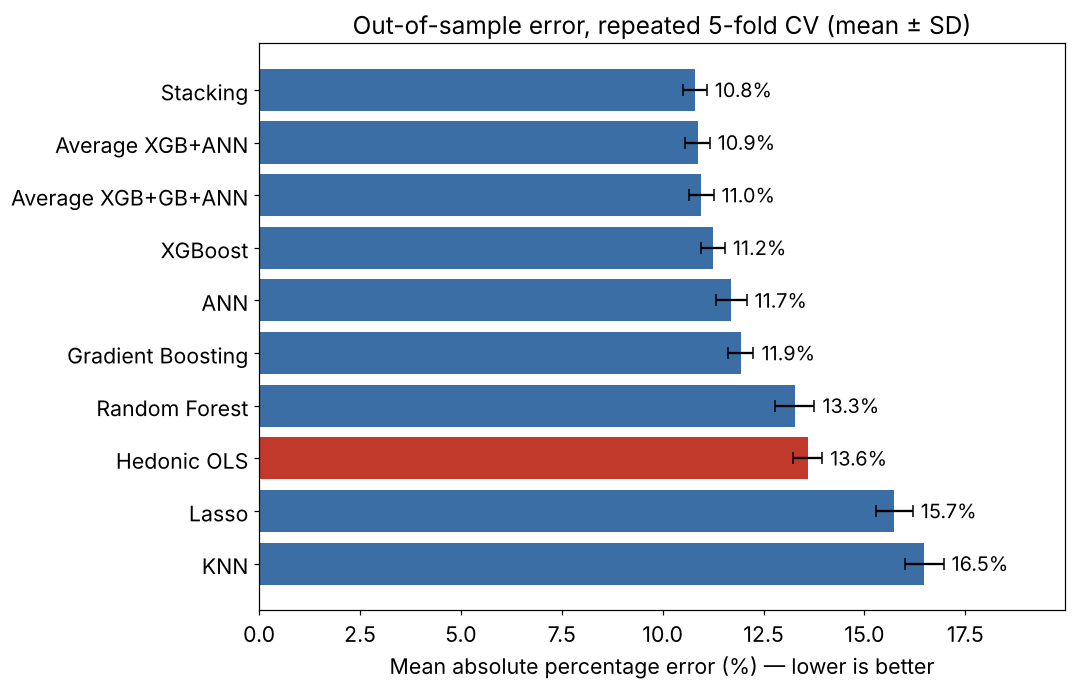

In [8]:
s = cv[cv.subset == "All cars"].groupby("model").MAPE.agg(["mean", "std"]).sort_values("mean", ascending=False)
fig, ax = plt.subplots(figsize=(10, 6.5))
ax.barh(s.index, s["mean"], xerr=s["std"], color=["#c0392b" if m == "Hedonic OLS" else "#3b6ea5" for m in s.index], capsize=4)
for i, v in enumerate(s["mean"]):
    ax.text(v + s["std"].iloc[i] + 0.2, i, f"{v:.1f}%", va="center", fontsize=13)
ax.set_xlabel("Mean absolute percentage error (%) — lower is better")
ax.set_title("Out-of-sample error, repeated 5-fold CV (mean ± SD)")
ax.set_xlim(0, s["mean"].max() + s["std"].max() + 3)
plt.tight_layout(); plt.savefig(f"{OUT}/fig_cv_mape.png", dpi=300); plt.show()

## 4. Are the differences statistically significant?

Fold results are not independent because the training sets overlap, so a plain paired *t*-test is too optimistic. The **corrected resampled *t*-test** (Nadeau & Bengio, 2003; Bouckaert & Frank, 2004) inflates the variance by the factor (1/J + n_test/n_train), where J is the number of folds.

In [9]:
def corrected_t(a, b, n_tr, n_te):
    diff = np.asarray(a) - np.asarray(b); J = len(diff)
    t = diff.mean() / np.sqrt((1 / J + n_te / n_tr) * diff.var(ddof=1))
    return diff.mean(), t, 2 * stats.t.sf(abs(t), J - 1)

sub = cv[cv.subset == "All cars"]
n_tr, n_te = sub.n_train.iloc[0], sub.n_test.iloc[0]
get = lambda m, met: sub[sub.model == m].sort_values("fold")[met].values
best = sub.groupby("model").MAPE.mean().idxmin()
out = []
for m in sub.model.unique():
    if m == best: continue
    r = {"Model": m}
    for met in ["MAPE", "RMSE"]:
        diff, t, p = corrected_t(get(m, met), get(best, met), n_tr, n_te)
        r[f"{met} worse by"], r[f"{met} p-value"] = round(diff, 3), round(p, 4)
    out.append(r)
sig = pd.DataFrame(out).sort_values("MAPE worse by").set_index("Model")
sig.to_csv(f"{OUT}/table4_significance_vs_best.csv")
print(f"Best model by MAPE: {best}")
display(sig)

pairs = [("Average XGB+ANN", "XGBoost"), ("Stacking", "XGBoost"), ("XGBoost", "Hedonic OLS"), ("Stacking", "Hedonic OLS")]
pair_rows = []
for a_, b_ in pairs:
    for met in ["MAPE", "RMSE", "R2"]:
        diff, t, p = corrected_t(get(a_, met), get(b_, met), n_tr, n_te)
        pair_rows.append({"Comparison": f"{a_} − {b_}", "Metric": met, "Difference": round(diff, 4), "t": round(t, 2), "p-value": round(p, 4)})
pair_tab = pd.DataFrame(pair_rows)
pair_tab.to_csv(f"{OUT}/table4b_key_comparisons.csv", index=False)
pair_tab

Best model by MAPE: Stacking


,MAPE worse by,MAPE p-value,RMSE worse by,RMSE p-value
Model,,,,
Average XGB+ANN,0.064,0.2618,0.031,0.7779
Average XGB+GB+ANN,0.159,0.0083,0.021,0.7123
XGBoost,0.448,0.0000,0.132,0.1185
ANN,0.899,0.0000,0.446,0.3051
Gradient Boosting,1.132,0.0000,0.211,0.0036
Random Forest,2.477,0.0000,0.473,0.0016
Hedonic OLS,2.795,0.0000,0.843,0.0001
Lasso,4.943,0.0000,2.199,0.0106
KNN,5.683,0.0000,1.067,0.0000


,Comparison,Metric,Difference,t,p-value
0,Average XGB+ANN − XGBoost,MAPE,-0.3841,-4.85,0.0003
1,Average XGB+ANN − XGBoost,RMSE,-0.1008,-0.67,0.5160
2,Average XGB+ANN − XGBoost,R2,0.0047,0.69,0.5020
3,Stacking − XGBoost,MAPE,-0.4484,-6.03,0.0000
4,Stacking − XGBoost,RMSE,-0.1320,-1.66,0.1185
5,Stacking − XGBoost,R2,0.0057,1.54,0.1450
6,XGBoost − Hedonic OLS,MAPE,-2.3466,-13.83,0.0000
7,XGBoost − Hedonic OLS,RMSE,-0.7108,-3.41,0.0043
8,XGBoost − Hedonic OLS,R2,0.0337,3.14,0.0072
9,Stacking − Hedonic OLS,MAPE,-2.7949,-17.56,0.0000


## 5. Prediction intervals with conformal prediction (CV+)

**CV+** (Barber, Candès, Ramdas & Tibshirani, 2021, *Annals of Statistics*) turns any model into prediction intervals with a finite-sample coverage guarantee: at least 1 − 2α in theory, and usually close to the nominal 1 − α in practice. The model is fitted in K = 5 folds of the training data, and the out-of-fold residuals set the interval width. On the log scale, the intervals are proportional to the price.

Coverage is checked on held-out cars: intervals are built from the training part of each outer fold only.

In [10]:
CONFORMAL_MODEL = "XGBoost"

class CVPlus:
    def __init__(self, make_model, K=5, seed=0):
        self.make_model, self.K, self.seed = make_model, K, seed
    def fit(self, X, log_y):
        kf = KFold(self.K, shuffle=True, random_state=self.seed)
        self.models_, self.res_, self.fold_ = [], np.zeros(len(log_y)), np.zeros(len(log_y), int)
        for k, (tr, va) in enumerate(kf.split(X)):
            m = self.make_model().fit(X.iloc[tr], log_y[tr])
            self.res_[va] = np.abs(log_y[va] - m.predict(X.iloc[va])); self.fold_[va] = k
            self.models_.append(m)
        return self
    def predict(self, X, alpha=0.10):
        mu = np.stack([m.predict(X) for m in self.models_])
        M = mu[self.fold_]
        lo, hi = M - self.res_[:, None], M + self.res_[:, None]
        n = len(self.res_)
        kl, kh = int(np.floor(alpha * (n + 1))) - 1, int(np.ceil((1 - alpha) * (n + 1))) - 1
        return np.exp(mu.mean(0)), np.exp(np.partition(lo, kl, axis=0)[kl]), np.exp(np.partition(hi, kh, axis=0)[kh])
    def __getstate__(self):
        state = self.__dict__.copy(); state["make_model"] = None
        return state

make_base = lambda seed=0: model_zoo(seed)[CONFORMAL_MODEL].regressor
recs = []
for f, (tr, te) in enumerate(KFold(5, shuffle=True, random_state=7).split(X)):
    cp = CVPlus(lambda: make_base(f), seed=f).fit(X.iloc[tr], np.log(y[tr]))
    for a in [0.20, 0.10, 0.05]:
        pt, lo, hi = cp.predict(X.iloc[te], alpha=a)
        recs.append(pd.DataFrame(dict(level=f"{100 - 100 * a:.0f}%", y=y[te], pred=pt, lo=lo, hi=hi)))
iv = pd.concat(recs)
iv["covered"] = (iv.y >= iv.lo) & (iv.y <= iv.hi)
iv["width"] = iv.hi - iv.lo
iv["lower_pct"], iv["upper_pct"] = (iv.lo / iv.pred - 1) * 100, (iv.hi / iv.pred - 1) * 100
conf = iv.groupby("level").agg(coverage_pct=("covered", lambda s: 100 * s.mean()), median_width_lakh=("width", "median"),
                               lower_bound_pct=("lower_pct", "median"), upper_bound_pct=("upper_pct", "median")).round(2)
conf.to_csv(f"{OUT}/table5_conformal_coverage.csv")
display(conf)

band = iv[iv.level == "90%"].assign(band=lambda t: pd.cut(t.pred, [0, 3, 5, 10, 20, 1000], labels=["< 3", "3–5", "5–10", "10–20", "> 20"]))
bandt = band.groupby("band", observed=True).agg(cars=("covered", "size"), coverage_pct=("covered", lambda s: 100 * s.mean()),
                                                median_width_lakh=("width", "median")).round(2)
bandt.to_csv(f"{OUT}/table5b_conformal_by_price_band.csv")
display(bandt)

,coverage_pct,median_width_lakh,lower_bound_pct,upper_bound_pct
level,,,,
80%,82.46,2.00,-16.37,19.57
90%,91.94,2.84,-22.40,28.83
95%,95.95,3.80,-28.52,39.86


,cars,coverage_pct,median_width_lakh
band,,,
< 3,1071,87.11,1.17
3–5,1529,92.22,2.02
5–10,1882,95.16,3.32
10–20,827,89.60,6.87
> 20,684,92.84,15.45


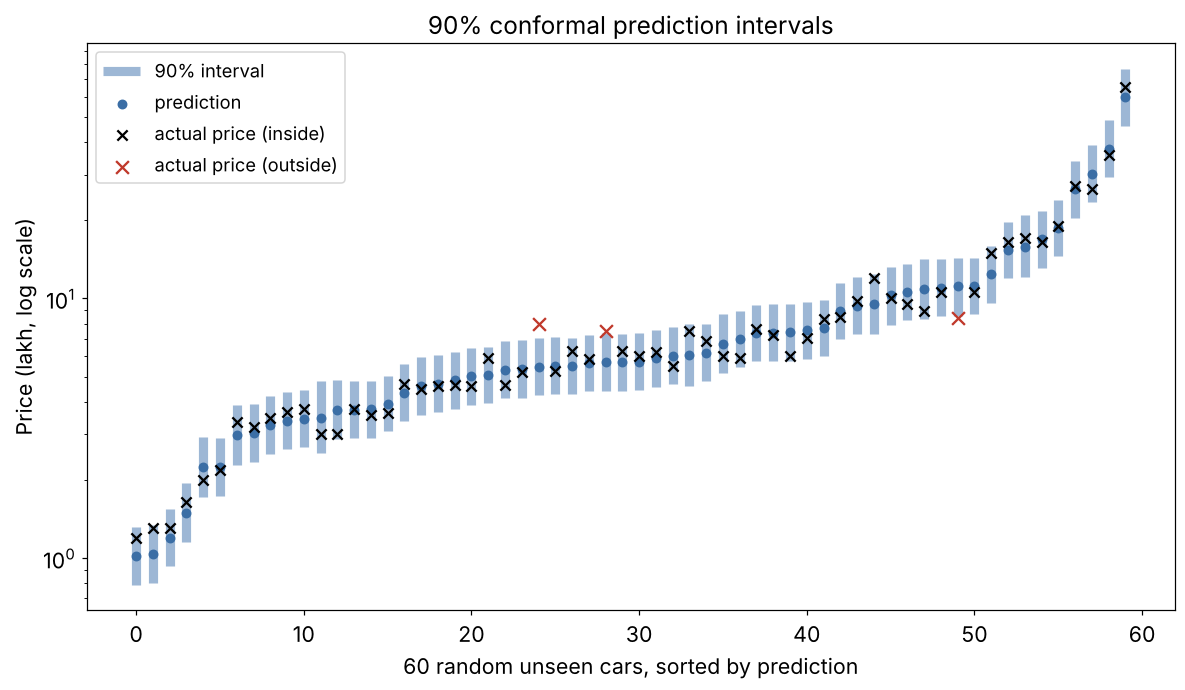

In [11]:
ex = iv[iv.level == "90%"].sample(60, random_state=3).sort_values("pred").reset_index(drop=True)
fig, ax = plt.subplots(figsize=(11, 6.5))
ax.vlines(ex.index, ex.lo, ex.hi, color="#9db7d5", lw=6, label="90% interval")
ax.scatter(ex.index, ex.pred, color="#3b6ea5", s=30, zorder=3, label="prediction")
miss = ~ex.covered
ax.scatter(ex.index[~miss], ex.y[~miss], color="black", marker="x", s=45, zorder=4, label="actual price (inside)")
ax.scatter(ex.index[miss], ex.y[miss], color="#c0392b", marker="x", s=70, zorder=4, label="actual price (outside)")
ax.set_yscale("log"); ax.set_ylabel("Price (lakh, log scale)"); ax.set_xlabel("60 random unseen cars, sorted by prediction")
ax.set_title("90% conformal prediction intervals"); ax.legend(fontsize=12)
plt.tight_layout(); plt.savefig(f"{OUT}/fig_conformal_intervals.png", dpi=300); plt.show()

## 6. What drives used-car prices?

### 6.1 SHAP values (XGBoost fitted on all cars)

For each original feature, the SHAP values of its one-hot columns are summed, so that e.g. *City* is one bar.

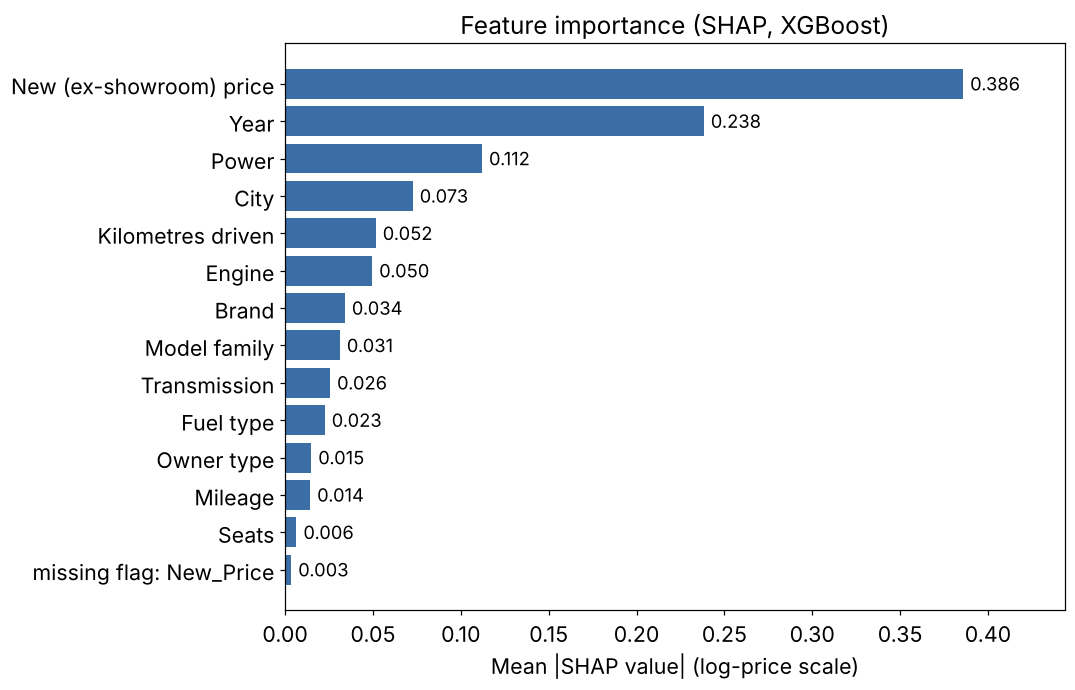

In [12]:
pipe = model_zoo(0)["XGBoost"].regressor.fit(X, np.log(y))
pre, xgb = pipe[0], pipe[-1]
Xt, names = pre.transform(X), pre.get_feature_names_out()
sv = shap.TreeExplainer(xgb).shap_values(Xt)

def group(nm):
    for c in CAT:
        if nm.startswith(c + "_"): return c
    return nm.replace("missingindicator_", "missing flag: ")

G = pd.DataFrame(sv, columns=names).T.groupby([group(n) for n in names]).sum().T
imp = G.abs().mean().sort_values()
imp = imp[imp > 0.002]
imp.sort_values(ascending=False).round(4).to_csv(f"{OUT}/table6_shap_importance.csv", header=["mean_abs_shap"])
label = {"Kilometers_Driven": "Kilometres driven", "New_Price": "New (ex-showroom) price", "Family": "Model family",
         "Fuel_Type": "Fuel type", "Owner_Type": "Owner type", "Location": "City"}
fig, ax = plt.subplots(figsize=(10, 6.5))
ax.barh([label.get(i, i) for i in imp.index], imp.values, color="#3b6ea5")
for i, v in enumerate(imp.values):
    ax.text(v + 0.004, i, f"{v:.3f}", va="center", fontsize=12)
ax.set_xlim(0, imp.max() * 1.15)
ax.set_xlabel("Mean |SHAP value| (log-price scale)"); ax.set_title("Feature importance (SHAP, XGBoost)")
plt.tight_layout(); plt.savefig(f"{OUT}/fig_shap_importance.png", dpi=300); plt.show()

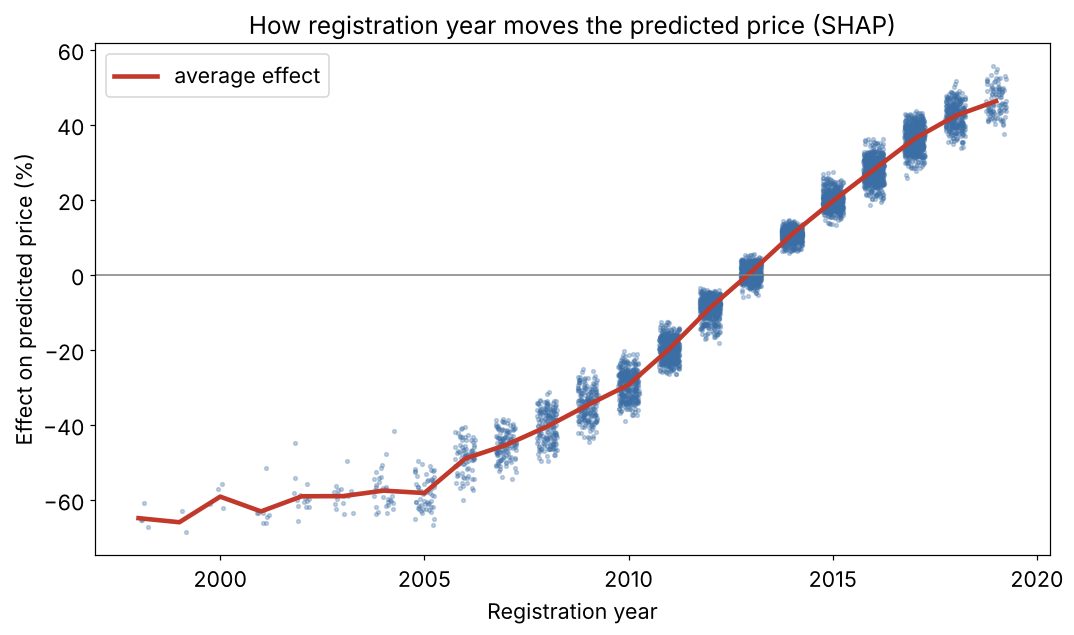

In [13]:
yi = list(names).index("Year")
fig, ax = plt.subplots(figsize=(10, 6))
jit = np.random.default_rng(0).uniform(-.25, .25, len(d))
ax.scatter(d.Year + jit, (np.exp(sv[:, yi]) - 1) * 100, s=6, alpha=.3, color="#3b6ea5")
mean_eff = pd.Series(sv[:, yi]).groupby(d.Year.values).mean()
ax.plot(mean_eff.index, (np.exp(mean_eff) - 1) * 100, color="#c0392b", lw=3, label="average effect")
ax.axhline(0, color="grey", lw=1)
ax.set_xlabel("Registration year"); ax.set_ylabel("Effect on predicted price (%)")
ax.set_title("How registration year moves the predicted price (SHAP)"); ax.legend()
plt.tight_layout(); plt.savefig(f"{OUT}/fig_shap_year.png", dpi=300); plt.show()

### 6.2 Hedonic regression: interpretable market effects

This is a log-price regression on diesel and petrol cars, with model-family fixed effects and heteroskedasticity-robust (HC1) standard errors. Each coefficient compares cars **of the same model family** that differ in one attribute, and is converted to a % price difference. The listings date from 2019, so age = 2019 − registration year.

In [14]:
h = d[d.Fuel_Type.isin(["Diesel", "Petrol"])].copy()
h["Age"], h["lp"], h["lkm"] = 2019 - h.Year, np.log(h.Price), np.log(h.Kilometers_Driven)
h["Transmission"] = pd.Categorical(h.Transmission, ["Manual", "Automatic"])
h["Owner_Type"] = pd.Categorical(h.Owner_Type, ["First", "Second", "Third", "Fourth & Above"])
h["Location"] = pd.Categorical(h.Location, ["Delhi"] + sorted(set(h.Location) - {"Delhi"}))
hed = smf.ols("lp ~ Age*C(Fuel_Type) + lkm + C(Transmission) + C(Owner_Type) + C(Location) + C(Family)", h).fit(cov_type="HC1")

terms = {"Age": ("One more year of age (diesel)", 1), "Age:C(Fuel_Type)[T.Petrol]": ("…additional yearly effect if petrol", 1),
         "lkm": ("Doubling kilometres driven", np.log(2)), "C(Transmission)[T.Automatic]": ("Automatic vs manual", 1),
         "C(Owner_Type)[T.Second]": ("Second vs first owner", 1), "C(Owner_Type)[T.Third]": ("Third vs first owner", 1)}
terms.update({k: (f"{k.split('T.')[1][:-1]} vs Delhi", 1) for k in hed.params.index if k.startswith("C(Location)")})
eff = pd.DataFrame([{"Effect": lab, "% price change": 100 * (np.exp(hed.params[k] * s) - 1),
                     "95% CI low": 100 * (np.exp((hed.params[k] - 1.96 * hed.bse[k]) * s) - 1),
                     "95% CI high": 100 * (np.exp((hed.params[k] + 1.96 * hed.bse[k]) * s) - 1),
                     "p-value": hed.pvalues[k]} for k, (lab, s) in terms.items()]).set_index("Effect").round(3)
eff.to_csv(f"{OUT}/table7_hedonic_effects.csv")
print(f"n = {int(hed.nobs)}, R² (log scale) = {hed.rsquared:.3f}, model families = {h.Family.nunique()}")
eff

n = 5926, R² (log scale) = 0.964, model families = 217


,% price change,95% CI low,95% CI high,p-value
Effect,,,,
One more year of age (diesel),-10.711,-11.031,-10.390,0.00
…additional yearly effect if petrol,0.300,-0.109,0.709,0.15
Doubling kilometres driven,-4.729,-5.439,-4.014,0.00
Automatic vs manual,13.091,11.402,14.805,0.00
Second vs first owner,-6.084,-7.446,-4.701,0.00
Third vs first owner,-13.209,-17.132,-9.100,0.00
Ahmedabad vs Delhi,9.760,6.933,12.662,0.00
Bangalore vs Delhi,29.398,26.478,32.386,0.00
Chennai vs Delhi,15.416,12.909,17.979,0.00


### 6.3 An India-specific pattern: old diesel cars are missing from Delhi listings

Since 2015, diesel vehicles older than 10 years have been barred from Delhi-NCR roads (National Green Tribunal order, upheld by the Supreme Court in 2018). If the rule affects the market, old diesels should be rare among Delhi listings.

In [15]:
old = h[h.Age >= 10]
share = old.groupby("Location", observed=True).Fuel_Type.apply(lambda s: 100 * (s == "Diesel").mean()).sort_values()
delhi = pd.DataFrame({"diesel share among 10+ year-old listings (%)": share.round(1),
                      "10+ year-old listings": old.Location.value_counts()[share.index]})
delhi.to_csv(f"{OUT}/table8_old_diesel_by_city.csv")
print(delhi)
tab = pd.crosstab(old.Location == "Delhi", old.Fuel_Type == "Diesel")
odds, p = stats.fisher_exact(tab.values)
print(f"\nFisher exact test, Delhi vs other cities: odds ratio = {odds:.2f}, p = {p:.4f}")

            diesel share among 10+ year-old listings (%)  10+ year-old listings
Location                                                                       
Delhi                                                8.6                     35
Kochi                                               16.7                     12
Ahmedabad                                           22.2                     27
Kolkata                                             23.4                     47
Jaipur                                              25.0                     80
Pune                                                27.7                    119
Coimbatore                                          31.2                     16
Mumbai                                              33.0                     94
Chennai                                             40.5                    116
Bangalore                                           43.5                     46
Hyderabad                               

## 7. Final model for the web app

The model is fitted on **all** cars and wrapped in CV+, so the app can show a 90% price range next to the point prediction. Accuracy figures must come from sections 3–5, never from this model, because it has seen every car.

In [16]:
final = CVPlus(lambda: make_base(0), K=5, seed=0).fit(X, np.log(y))
joblib.dump(final, "car_price_cvplus_xgb.joblib")
example = pd.DataFrame([{"Year": 2015, "Kilometers_Driven": 45000, "Mileage": 22.0, "Power": 74.0, "Engine": 1248,
                         "Seats": 5, "New_Price": 7.5, "Brand": "Maruti", "Family": "maruti swift", "Location": "Pune",
                         "Fuel_Type": "Diesel", "Transmission": "Manual", "Owner_Type": "First"}])
pt, lo, hi = final.predict(example[NUM + CAT], alpha=0.10)
print(f"Predicted price: {pt[0]:.2f} lakh; 90% range {lo[0]:.2f}–{hi[0]:.2f} lakh")

Predicted price: 5.40 lakh; 90% range 4.25–6.89 lakh


## 8. Files for the paper

In [17]:
for f in sorted(os.listdir(OUT)):
    print(f)

cv_results_by_fold.csv
fig_conformal_intervals.png
fig_cv_mape.png
fig_shap_importance.png
fig_shap_year.png
table1_descriptive_categorical.csv
table1_descriptive_numeric.csv
table2_pipeline_comparison.csv
table3_cv_all_cars.csv
table3b_cv_trimmed_scope.csv
table4_significance_vs_best.csv
table4b_key_comparisons.csv
table5_conformal_coverage.csv
table5b_conformal_by_price_band.csv
table6_shap_importance.csv
table7_hedonic_effects.csv
table8_old_diesel_by_city.csv
